# A Drone in SymPy

A 1 kg quadcopter, from "how much power does it take to hover?" to
"what does a flight cost?".

| Part | Question | Physics / math |
|---|---|---|
| 1 | How much power does hovering take? | momentum theory: pushing air down |
| 2 | How does the drone move? | Lagrange's equations, derived in SymPy |
| 3 | Can four motors control six motions? | linearise about hover; controllability |
| 4 | How do you make it fly to a point? | LQR feedback, simulated on the full nonlinear model |
| 5 | How long does it fly, and what does it cost? | battery energy, electricity price, battery wear |

All numbers describe a generic, illustrative 1 kg quadcopter with
10-inch propellers and a 4-cell lithium battery; they are not the
specification of any particular product. Every result is asserted.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.linalg import solve_continuous_are

sp.init_printing()
params = {
    "mass_kg": 1.0,
    "g": 9.81,
    "arm_m": 0.20,                 # motor distance from the centre
    "inertia_kgm2": 0.010,         # moment of inertia about the roll axis
    "prop_diameter_m": 0.254,      # 10-inch propellers
    "n_rotors": 4,
    "air_density": 1.225,          # kg/m^3, sea level
    "max_thrust_to_weight": 2.0,
}
print(params)

{'mass_kg': 1.0, 'g': 9.81, 'arm_m': 0.2, 'inertia_kgm2': 0.01, 'prop_diameter_m': 0.254, 'n_rotors': 4, 'air_density': 1.225, 'max_thrust_to_weight': 2.0}


# Part 1 — Hover power from momentum theory

A rotor holds the drone up by throwing air downward. Each second it
accelerates a mass of air $\dot m = \rho A v$ through its disc (area
$A$) to speed $v$ at the disc. Momentum theory for an ideal rotor gives
thrust $T = 2\rho A v^2$ and power $P = Tv$. Eliminating $v$:

$$P_\text{ideal} = \sqrt{\frac{T^3}{2\rho A}} .$$

The **bigger the disc, the less power** for the same thrust — moving a
lot of air slowly is cheaper than a little air fast. That is why
helicopters have long blades and why bigger propellers fly longer.

Real rotors waste some power (tip losses, drag). The **figure of merit**
(about 0.5–0.7 for small propellers) is the ideal power divided by the
actual shaft power, and the motors and speed controllers lose more.

In [2]:
T, rho, A, v = sp.symbols("T rho A v", positive=True)
thrust_eq = sp.Eq(T, 2 * rho * A * v**2)
v_induced = sp.solve(thrust_eq, v)[0]
P_ideal = sp.simplify(T * v_induced)
print("induced velocity v ="); sp.pprint(v_induced)
print("\nideal hover power P = T v ="); sp.pprint(P_ideal)
assert sp.simplify(P_ideal - sp.sqrt(T**3 / (2 * rho * A))) == 0

weight = params["mass_kg"] * params["g"]
disc_area = params["n_rotors"] * np.pi * (params["prop_diameter_m"] / 2) ** 2
p_ideal = float(P_ideal.subs({T: weight, rho: params["air_density"], A: disc_area}))
figure_of_merit, drive_efficiency = 0.60, 0.80          # illustrative
p_electrical = p_ideal / (figure_of_merit * drive_efficiency)
print(f"\ntotal disc area {disc_area:.3f} m^2, weight {weight:.2f} N")
print(f"ideal hover power      {p_ideal:6.1f} W")
print(f"electrical hover power {p_electrical:6.1f} W   (figure of merit {figure_of_merit}, drive {drive_efficiency})")
assert abs(p_ideal - 43.6) < 0.2

induced velocity v =
 √2⋅√T 
───────
2⋅√A⋅√ρ

ideal hover power P = T v =
    3/2
√2⋅T   
───────
2⋅√A⋅√ρ

total disc area 0.203 m^2, weight 9.81 N
ideal hover power        43.6 W
electrical hover power   90.8 W   (figure of merit 0.6, drive 0.8)


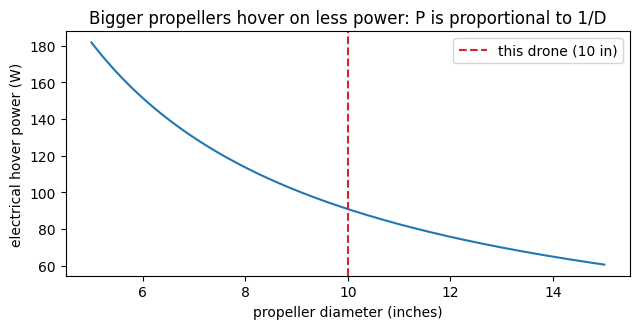

In [3]:
diameters_in = np.linspace(5, 15, 200)
areas = params["n_rotors"] * np.pi * (diameters_in * 0.0254 / 2) ** 2
power_curve = np.sqrt(weight**3 / (2 * params["air_density"] * areas)) / (figure_of_merit * drive_efficiency)
plt.figure(figsize=(6.5, 3.4))
plt.plot(diameters_in, power_curve)
plt.axvline(10, color="C3", ls="--", label="this drone (10 in)")
plt.xlabel("propeller diameter (inches)"); plt.ylabel("electrical hover power (W)")
plt.title("Bigger propellers hover on less power: P is proportional to 1/D"); plt.legend()
plt.tight_layout(); plt.show()

# Part 2 — Equations of motion, derived

To keep the algebra readable, look at the drone from the side: a
**planar quadrotor** moving sideways ($y$), up ($z$) and tilting
($\theta$). Two motor pairs, left and right, a distance $\ell$ from the
centre, push along the drone's own "up" direction.

- Total thrust $u_1 = T_L + T_R$ acts along the tilted body axis,
  $(-\sin\theta, \cos\theta)$.
- The thrust difference makes a torque $u_2 = \ell\,(T_R - T_L)$.

**Lagrange's method:** write the kinetic minus potential energy,
$\mathcal L = \tfrac12 m(\dot y^2 + \dot z^2) + \tfrac12 I\dot\theta^2 - mgz$,
then for each coordinate $q$:

$$\frac{d}{dt}\frac{\partial\mathcal L}{\partial \dot q} - \frac{\partial\mathcal L}{\partial q} = Q_q ,$$

where $Q_q$ is the generalised force from the motors.

In [4]:
t = sp.symbols("t")
m, g, I, ell = sp.symbols("m g I ell", positive=True)
u1, u2 = sp.symbols("u_1 u_2", real=True)
y, z, th = [sp.Function(name)(t) for name in ("y", "z", "theta")]

lagrangian = sp.Rational(1, 2) * m * (y.diff(t)**2 + z.diff(t)**2) + sp.Rational(1, 2) * I * th.diff(t)**2 - m * g * z
generalised_force = {y: -u1 * sp.sin(th), z: u1 * sp.cos(th), th: u2}

equations = []
for q in (y, z, th):
    lhs = sp.diff(lagrangian.diff(q.diff(t)), t) - lagrangian.diff(q)
    equations.append(sp.Eq(lhs, generalised_force[q]))
    sp.pprint(equations[-1]); print()

accelerations = sp.solve(equations, [y.diff(t, 2), z.diff(t, 2), th.diff(t, 2)])
for q in (y, z, th):
    print(f"{str(q.func):5s}'' =", accelerations[q.diff(t, 2)])
assert sp.simplify(accelerations[z.diff(t, 2)] - (u1 * sp.cos(th) / m - g)) == 0

   2                       
  d                        
m⋅───(y(t)) = -u₁⋅sin(θ(t))
    2                      
  dt                       

         2                      
        d                       
g⋅m + m⋅───(z(t)) = u₁⋅cos(θ(t))
          2                     
        dt                      

   2            
  d             
I⋅───(θ(t)) = u₂
    2           
  dt            

y    '' = -u_1*sin(theta(t))/m
z    '' = (-g*m + u_1*cos(theta(t)))/m
theta'' = u_2/I


Read the three equations:

- **Sideways:** $\ddot y = -\dfrac{u_1}{m}\sin\theta$. A drone has no
  sideways thruster. It moves sideways only by *tilting* so part of its
  thrust points that way.
- **Vertical:** $\ddot z = \dfrac{u_1}{m}\cos\theta - g$. Tilting steals
  lift, so a tilted drone must push harder to hold altitude.
- **Tilt:** $\ddot\theta = u_2 / I$. Differential thrust spins it.

# Part 3 — Linearise about hover

Near hover ($\theta \approx 0$, $u_1 \approx mg$) the equations are
almost linear. Writing the state as
$\mathbf x = (y, z, \theta, \dot y, \dot z, \dot\theta)$ and the input as
$(\delta u_1, u_2)$ with $u_1 = mg + \delta u_1$, the Jacobians give
$\dot{\mathbf x} \approx A\mathbf x + B\mathbf u$.

In [5]:
Y, Z, TH, VY, VZ, W = sp.symbols("y z theta v_y v_z omega", real=True)
du1 = sp.Symbol("delta_u1", real=True)
state = sp.Matrix([Y, Z, TH, VY, VZ, W])
inputs = sp.Matrix([du1, u2])

replace = {th: TH, u1: m * g + du1}
f = sp.Matrix([VY, VZ, W,
               accelerations[y.diff(t, 2)].subs(replace),
               accelerations[z.diff(t, 2)].subs(replace),
               accelerations[th.diff(t, 2)].subs(replace)])
hover = {Y: 0, Z: 0, TH: 0, VY: 0, VZ: 0, W: 0, du1: 0, u2: 0}
A_sym = f.jacobian(state).subs(hover)
B_sym = f.jacobian(inputs).subs(hover)
print("A ="); sp.pprint(A_sym)
print("\nB ="); sp.pprint(B_sym)

controllability = sp.Matrix.hstack(*[A_sym**k * B_sym for k in range(6)])
print("\nrank of the controllability matrix:", controllability.rank(), "of 6")
assert A_sym[3, 2] == -g and controllability.rank() == 6

A =
⎡0  0  0   1  0  0⎤
⎢                 ⎥
⎢0  0  0   0  1  0⎥
⎢                 ⎥
⎢0  0  0   0  0  1⎥
⎢                 ⎥
⎢0  0  -g  0  0  0⎥
⎢                 ⎥
⎢0  0  0   0  0  0⎥
⎢                 ⎥
⎣0  0  0   0  0  0⎦

B =
⎡0  0⎤
⎢    ⎥
⎢0  0⎥
⎢    ⎥
⎢0  0⎥
⎢    ⎥
⎢0  0⎥
⎢    ⎥
⎢1   ⎥
⎢─  0⎥
⎢m   ⎥
⎢    ⎥
⎢   1⎥
⎢0  ─⎥
⎣   I⎦

rank of the controllability matrix: 6 of 6


The entry $-g$ in $A$ is the whole story of sideways flight:
$\ddot y = -g\,\theta$. The controllability matrix has full rank 6, so
the two inputs can steer all six states — sideways position is reached
*through* tilt, a chain of four integrations from $u_2$ to $y$.

# Part 4 — Flying to a point with LQR

A **linear-quadratic regulator** picks the feedback $\mathbf u = -K\mathbf x$
that minimises a weighted sum of position error and control effort,

$$J = \int_0^\infty \big(\mathbf x^{\mathsf T} Q\,\mathbf x + \mathbf u^{\mathsf T} R\,\mathbf u\big)\,dt .$$

$K$ comes from the algebraic Riccati equation. The gain is designed on
the linear model, but the simulation below uses the **full nonlinear
equations** from Part 2, and clips each motor's thrust to what it can
actually produce (zero to one times the drone's weight per motor pair).

In [6]:
numeric = {m: params["mass_kg"], g: params["g"], I: params["inertia_kgm2"], ell: params["arm_m"]}
A_num = np.array(A_sym.subs(numeric), dtype=float)
B_num = np.array(B_sym.subs(numeric), dtype=float)
Q = np.diag([3.0, 3.0, 1.0, 1.0, 1.0, 0.1])          # position weight 3: brisk, under ~35 deg of tilt
R = np.diag([1.0, 10.0])
P = solve_continuous_are(A_num, B_num, Q, R)
K = np.linalg.solve(R, B_num.T @ P)
closed_loop = np.linalg.eigvals(A_num - B_num @ K)
print("LQR gain K ="); print(np.round(K, 3))
print("closed-loop eigenvalues:", np.round(closed_loop, 2))
assert np.all(closed_loop.real < 0)

mass, grav, inertia, arm = params["mass_kg"], params["g"], params["inertia_kgm2"], params["arm_m"]
pair_max = params["max_thrust_to_weight"] * mass * grav / 2        # each side can push up to this


def motor_thrusts(x_state, target):
    error = x_state - target
    delta_u1, torque = -K @ error
    total = mass * grav + delta_u1
    right = np.clip((total + torque / arm) / 2, 0.0, pair_max)
    left = np.clip((total - torque / arm) / 2, 0.0, pair_max)
    return left, right


def dynamics(_, x_state, target):
    left, right = motor_thrusts(x_state, target)
    total, torque = left + right, arm * (right - left)
    _, _, theta, vy, vz, omega = x_state
    return [vy, vz, omega, -total * np.sin(theta) / mass, total * np.cos(theta) / mass - grav, torque / inertia]


target = np.array([2.0, 1.0, 0, 0, 0, 0])            # fly 2 m sideways and 1 m up
run = solve_ivp(dynamics, (0, 8), np.zeros(6), args=(target,), max_step=0.005, dense_output=True)
times = np.linspace(0, 8, 1600)
states = run.sol(times)
thrusts = np.array([motor_thrusts(states[:, k], target) for k in range(times.size)])

final_error = np.hypot(*(states[:2, -1] - target[:2]))
print(f"\nposition error after 8 s: {final_error * 1000:.2f} mm")
print(f"largest tilt: {np.degrees(np.abs(states[2]).max()):.1f} deg")
print(f"motor pair thrust stayed within 0 .. {pair_max:.2f} N: "
      f"min {thrusts.min():.2f} N, max {thrusts.max():.2f} N")
assert final_error < 0.01 and np.degrees(np.abs(states[2]).max()) < 40

LQR gain K =
[[-0.     1.732  0.    -0.     2.113 -0.   ]
 [-0.548 -0.     1.383 -0.504 -0.     0.194]]
closed-loop eigenvalues: [-9.97+0.j   -3.84+4.j   -3.84-4.j   -1.75+0.j   -1.06+0.78j -1.06-0.78j]



position error after 8 s: 0.06 mm
largest tilt: 34.2 deg
motor pair thrust stayed within 0 .. 9.81 N: min 3.03 N, max 8.51 N


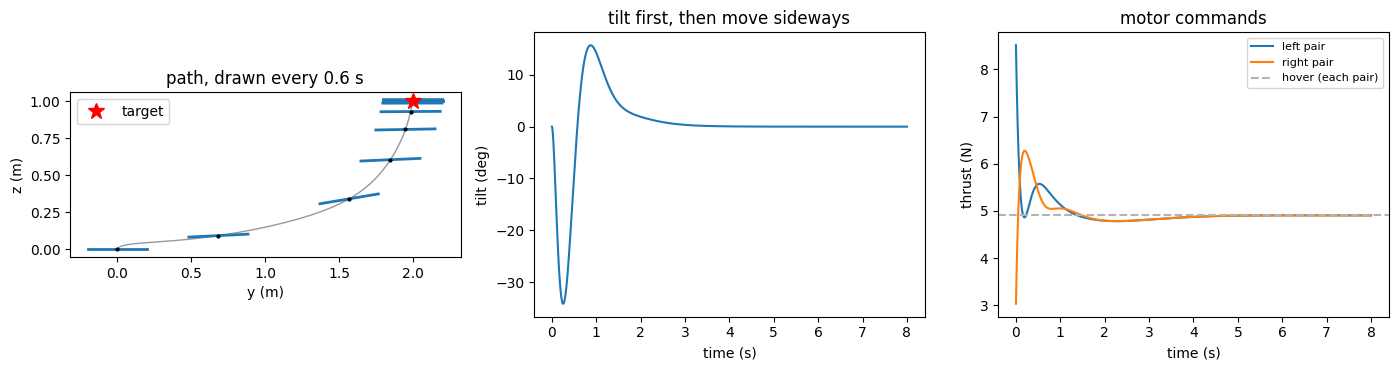

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(states[0], states[1], color="0.6", lw=1)
for k in range(0, times.size, 120):                    # draw the drone every 0.6 s
    cy, cz, angle = states[0, k], states[1, k], states[2, k]
    dy, dz = arm * np.cos(angle), arm * np.sin(angle)
    axes[0].plot([cy - dy, cy + dy], [cz - dz, cz + dz], "C0", lw=2)
    axes[0].plot(cy, cz, "ko", ms=2)
axes[0].plot(*target[:2], "r*", ms=12, label="target")
axes[0].set_aspect("equal"); axes[0].set_xlabel("y (m)"); axes[0].set_ylabel("z (m)")
axes[0].set_title("path, drawn every 0.6 s"); axes[0].legend()
axes[1].plot(times, np.degrees(states[2]))
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("tilt (deg)")
axes[1].set_title("tilt first, then move sideways")
axes[2].plot(times, thrusts[:, 0], label="left pair"); axes[2].plot(times, thrusts[:, 1], label="right pair")
axes[2].axhline(mass * grav / 2, color="0.7", ls="--", label="hover (each pair)")
axes[2].set_xlabel("time (s)"); axes[2].set_ylabel("thrust (N)"); axes[2].set_title("motor commands")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

Notice in the tilt plot that the drone first tilts *toward* the
target, accelerates, then tilts the other way to brake — exactly what
$\ddot y = -g\theta$ requires. (With the sign convention here, a
negative tilt pushes toward $+y$.)

The weights in $Q$ set the drone's personality. A position weight of 10
reaches the target sooner but tilts past 50° with the motors saturated;
a weight of 1 keeps the tilt near 20° but is still a few millimetres off
after 8 s. The value 3 used here is a middle ground.

# Part 5 — How long does it fly, and what does it cost?

**Flight time** is usable battery energy divided by power. Lithium
batteries should not be drained completely; using 80 % is a common
rule of thumb.

**Cost per flight** has two parts:

- the **electricity** to recharge the battery, and
- **battery wear**: a lithium pack survives a limited number of charge
  cycles, so each flight uses up a slice of its price.

The prices below are illustrative assumptions — change them to your own.

In [8]:
cells_in_series, capacity_Ah = 4, 3.0
pack_voltage = 3.7 * cells_in_series                  # nominal volts
pack_energy_Wh = pack_voltage * capacity_Ah
usable_Wh = 0.80 * pack_energy_Wh
hover_minutes = usable_Wh / p_electrical * 60

electricity_usd_per_kWh = 0.30                        # illustrative
charger_efficiency = 0.90
battery_price_usd, battery_cycles = 60.0, 300         # illustrative
energy_cost = pack_energy_Wh / charger_efficiency / 1000 * electricity_usd_per_kWh
wear_cost = battery_price_usd / battery_cycles

print(f"battery: {cells_in_series}S {capacity_Ah:.1f} Ah = {pack_energy_Wh:.1f} Wh, usable {usable_Wh:.1f} Wh")
print(f"hover power {p_electrical:.0f} W  ->  hover time {hover_minutes:.1f} min")
print(f"\nelectricity per full recharge: ${energy_cost:.3f}")
print(f"battery wear per flight:       ${wear_cost:.2f}")
print(f"total per flight:              ${energy_cost + wear_cost:.2f}  "
      f"(the battery wear is {wear_cost / energy_cost:.0f}x the electricity)")
assert 20 < hover_minutes < 27 and wear_cost > energy_cost

battery: 4S 3.0 Ah = 44.4 Wh, usable 35.5 Wh
hover power 91 W  ->  hover time 23.5 min

electricity per full recharge: $0.015
battery wear per flight:       $0.20
total per flight:              $0.21  (the battery wear is 14x the electricity)


The electricity costs about a cent and a half; the battery wearing
out costs about fourteen times more. To make flights cheaper, look
after the battery (avoid deep discharge and storing it fully charged),
not the power bill.

Hover time is an upper bound for real flying: manoeuvring, wind and
climbing all draw more power than hovering, and this budget ignores the
power used by the electronics and camera.

# Summary

| Quantity | Equation | Value for this drone |
|---|---|---|
| Ideal hover power | $\sqrt{T^3/(2\rho A)}$ | 43.6 W |
| Electrical hover power | ideal ÷ (figure of merit × drive efficiency) | about 91 W |
| Sideways motion | $\ddot y = -(u_1/m)\sin\theta \approx -g\theta$ | move by tilting |
| Controllability | rank of $[B, AB, \dots, A^5B]$ | 6 of 6 |
| LQR | $u = -Kx$, $K$ from the Riccati equation | reaches a point 2 m away within 1 cm, tilting at most about 34° |
| Hover time | usable energy ÷ power | about 23 minutes |
| Cost per flight | electricity + battery wear | about 21 cents, mostly battery wear |

**What this leaves out:** the third dimension (the full quadrotor adds
pitch and yaw, but each axis looks like the one solved here), motor
dynamics and propeller response time, aerodynamic drag, wind, and sensor
noise. Those are the next steps toward a flight controller.